# Olympics ↔ Markets: Results Visualizations (Clarity-First)

This notebook **only** uses the `results_*.csv` outputs from your analysis notebook and generates a small set of **easy-to-read** figures.

Design choices for clarity:
- Values shown in **percent / basis points** where appropriate
- **Symmetric x-axes** around 0 so “positive vs negative” is obvious
- **Error bars (≈95% CI)** when possible
- **Small number of plots** that answer the biggest questions on first look


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---- File paths (assumes CSVs are in the same folder as this notebook) ----
from pathlib import Path
BASE = Path(".")  # if running elsewhere, set BASE = Path("/path/to/csvs")

PATHS = {
    "corr": BASE / "../results/results_corr_matrix.csv",
    "diff": BASE / "../results/results_diff_in_means.csv",
    "core": BASE / "../results/results_core_regressions_long.csv",
    "sector": BASE / "../results/results_sector_regressions_long.csv",
    "season": BASE / "../results/results_season_interaction_long.csv",
    "ll": BASE / "../results/results_lead_lag_long.csv",
    "car": BASE / "../results/results_car_summary.csv",
}

dfs = {k: pd.read_csv(v) for k, v in PATHS.items()}
corr = dfs["corr"]
diff = dfs["diff"]
core = dfs["core"]
sector = dfs["sector"]
season = dfs["season"]
ll = dfs["ll"]
car = dfs["car"]

def percent(x, pos=None):
    return f"{x*100:.1f}%"

def bps(x, pos=None):
    return f"{x*10000:.0f} bps"

def outcome_from_model(s: str) -> str:
    return s.split(" ~ ")[0].strip()

def add_outcome_col(df):
    out = df.copy()
    out["outcome"] = out["model"].apply(outcome_from_model)
    return out

def approx_se_from_t(coef, t):
    # if t is 0 or missing, return NaN
    try:
        if pd.isna(t) or t == 0:
            return np.nan
        return abs(coef / t)
    except Exception:
        return np.nan

def add_ci(df):
    out = df.copy()
    out["se_approx"] = [approx_se_from_t(c, t) for c, t in zip(out["coef"], out["t"])]
    out["ci_low"] = out["coef"] - 1.96*out["se_approx"]
    out["ci_high"] = out["coef"] + 1.96*out["se_approx"]
    return out

core2 = add_ci(add_outcome_col(core))
sector2 = add_ci(add_outcome_col(sector))
season2 = add_ci(add_outcome_col(season))
ll2 = add_ci(add_outcome_col(ll))

# For readability: treat 'ret_*' and 'abret_*' outcomes as returns (display in bps)
def is_return_outcome(outcome: str) -> bool:
    return outcome.startswith("ret_") or outcome.startswith("abret_") or outcome.endswith("_SPY") and outcome.startswith("ret")



## 1) Quick correlation overview
A compact heatmap so you can see what moves with what at a glance.

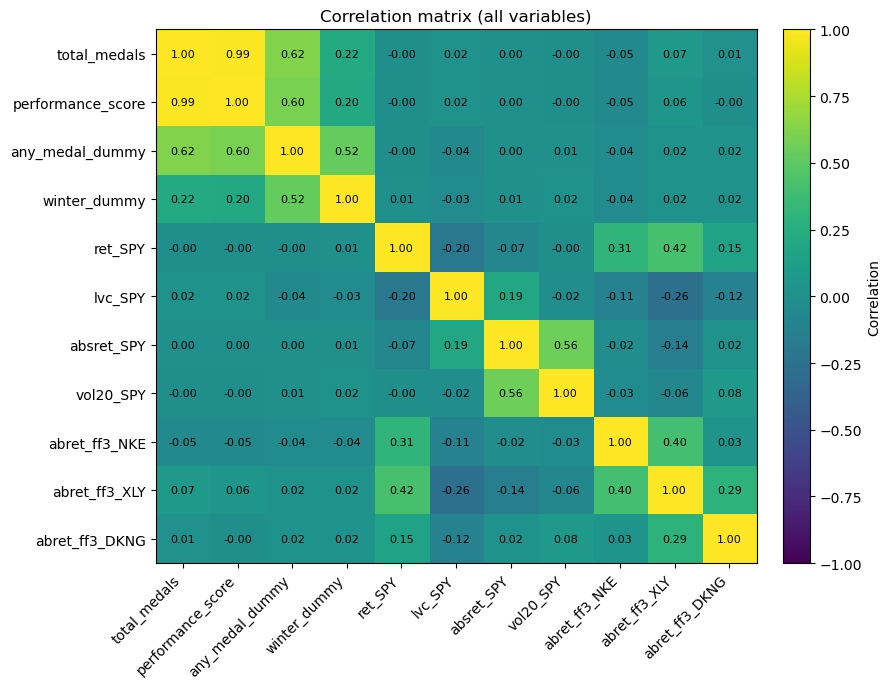

,total_medals,performance_score,any_medal_dummy,winter_dummy,ret_SPY,lvc_SPY,absret_SPY,vol20_SPY,abret_ff3_NKE,abret_ff3_XLY,abret_ff3_DKNG
var,,,,,,,,,,,
total_medals,1.000000,0.986276,0.619444,0.220156,-0.002847,0.016490,0.002857,-0.002079,-0.046685,0.070477,0.010132
performance_score,0.986276,1.000000,0.597474,0.203763,-0.002075,0.017374,0.002771,-0.003241,-0.048885,0.058037,-0.003891
any_medal_dummy,0.619444,0.597474,1.000000,0.524092,-0.002917,-0.041747,0.002602,0.005780,-0.035975,0.022516,0.015680
winter_dummy,0.220156,0.203763,0.524092,1.000000,0.005610,-0.033217,0.006405,0.020780,-0.035975,0.022516,0.015680
ret_SPY,-0.002847,-0.002075,-0.002917,0.005610,1.000000,-0.199154,-0.073673,-0.004537,0.312215,0.421366,0.149553
lvc_SPY,0.016490,0.017374,-0.041747,-0.033217,-0.199154,1.000000,0.189434,-0.017563,-0.111280,-0.262003,-0.115179
absret_SPY,0.002857,0.002771,0.002602,0.006405,-0.073673,0.189434,1.000000,0.561014,-0.018148,-0.143369,0.016987
vol20_SPY,-0.002079,-0.003241,0.005780,0.020780,-0.004537,-0.017563,0.561014,1.000000,-0.028150,-0.064009,0.076402
abret_ff3_NKE,-0.046685,-0.048885,-0.035975,-0.035975,0.312215,-0.111280,-0.018148,-0.028150,1.000000,0.401590,0.031407


In [3]:
# Correlation matrix file uses an 'Unnamed: 0' index column
cm = corr.copy()
if "Unnamed: 0" in cm.columns:
    cm = cm.rename(columns={"Unnamed: 0": "var"}).set_index("var")

# Make sure it's numeric
cm = cm.apply(pd.to_numeric, errors="coerce")

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm.values, aspect="auto", vmin=-1, vmax=1)

ax.set_xticks(range(len(cm.columns)))
ax.set_yticks(range(len(cm.index)))
ax.set_xticklabels(cm.columns, rotation=45, ha="right")
ax.set_yticklabels(cm.index)

# annotate (small matrix, annotations help)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm.values[i, j]
        if pd.isna(val): 
            continue
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8)

ax.set_title("Correlation matrix (all variables)")
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Correlation")

plt.tight_layout()
plt.show()

display(cm)


## 2) Medal day vs non‑medal day differences (simple + readable)
Horizontal bars with the sign obvious. Values are shown as **percent** when the metric looks like a return.

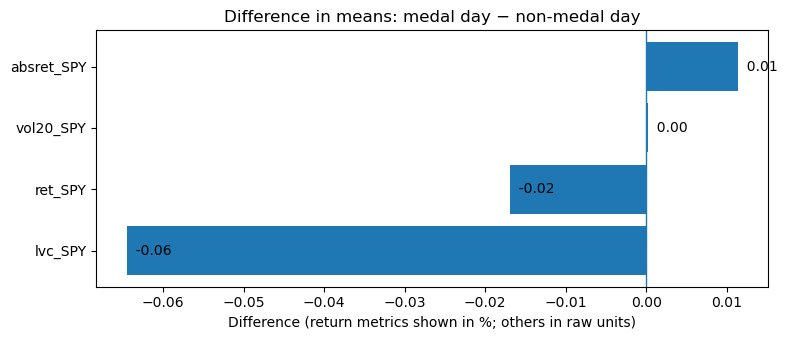

,metric,mean_medal,mean_nonmedal,diff,t,p,n_medal,n_nonmedal
1,lvc_SPY,-0.061965,0.002525,-0.064490,-3.120896,0.001974,281,5507
0,ret_SPY,0.000092,0.000261,-0.000170,-0.221062,0.825190,281,5507
3,vol20_SPY,0.010673,0.010487,0.000186,0.505275,0.613713,281,5507
2,absret_SPY,0.008353,0.008239,0.000114,0.198815,0.842538,281,5507


In [4]:
d = diff.copy()

# Heuristic: if metric name contains 'ret' treat as return-like
d["is_return"] = d["metric"].str.contains("ret", case=False, na=False)

# Create display values
d["diff_display"] = np.where(d["is_return"], d["diff"]*100, d["diff"])
d = d.sort_values("diff_display")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(d["metric"], d["diff_display"])
ax.axvline(0, linewidth=1)

ax.set_title("Difference in means: medal day − non‑medal day")
ax.set_xlabel("Difference (return metrics shown in %; others in raw units)")

# annotate values
for y, v in enumerate(d["diff_display"]):
    ax.text(v, y, f"  {v:.2f}", va="center")

plt.tight_layout()
plt.show()

display(d[["metric","mean_medal","mean_nonmedal","diff","t","p","n_medal","n_nonmedal"]])


## 3) Core regressions (most interpretable view)

For each outcome, we show only the **main medal variables**:
- `performance_score`
- `total_medals`
- `any_medal_dummy`

Plotted as **coefficient with ~95% CI** (approx from t-stat).

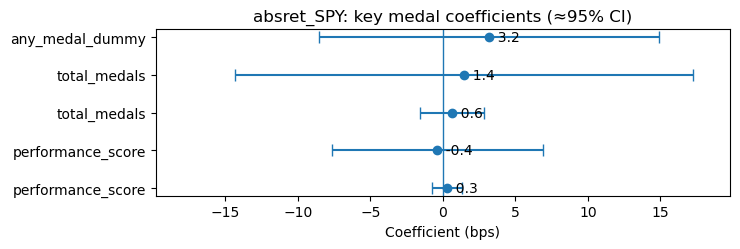

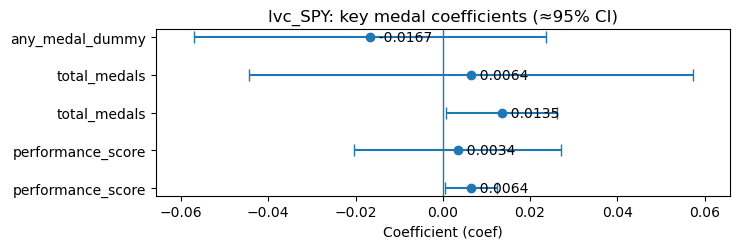

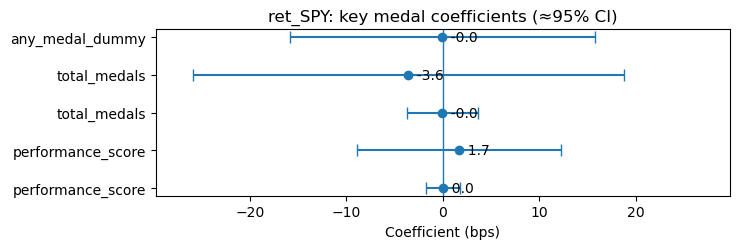

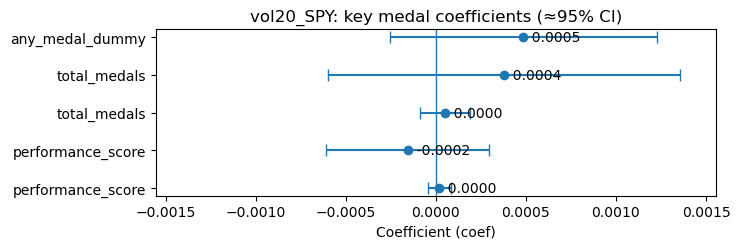

In [5]:
KEY = ["performance_score","total_medals","any_medal_dummy"]

for out in sorted(core2["outcome"].unique()):
    sub = core2[(core2["outcome"]==out) & (core2["param"].isin(KEY))].copy()
    if sub.empty:
        continue

    # For return-like outcomes, show in basis points for readability
    show_bps = ("ret_" in out) or out.startswith("ret") or out.startswith("abret")
    scale = 10000 if show_bps else 1
    unit = "bps" if show_bps else "coef"

    sub["coef_s"] = sub["coef"]*scale
    sub["ci_low_s"] = sub["ci_low"]*scale
    sub["ci_high_s"] = sub["ci_high"]*scale

    # Order rows consistently
    order = {p:i for i,p in enumerate(KEY)}
    sub["order"] = sub["param"].map(order)
    sub = sub.sort_values("order")

    # Symmetric x-limits around zero
    max_abs = np.nanmax(np.abs(np.r_[sub["ci_low_s"].values, sub["ci_high_s"].values]))
    if not np.isfinite(max_abs) or max_abs == 0:
        max_abs = np.nanmax(np.abs(sub["coef_s"].values)) if len(sub) else 1
    pad = 0.15*max_abs
    xlim = (-max_abs-pad, max_abs+pad)

    fig, ax = plt.subplots(figsize=(7.5, 2.6))
    y = np.arange(len(sub))

    ax.errorbar(sub["coef_s"], y, 
                xerr=[sub["coef_s"]-sub["ci_low_s"], sub["ci_high_s"]-sub["coef_s"]],
                fmt="o", capsize=4)
    ax.axvline(0, linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["param"])
    ax.set_xlim(*xlim)
    ax.set_title(f"{out}: key medal coefficients (≈95% CI)")
    ax.set_xlabel(f"Coefficient ({unit})")

    # label values on the right
    for yi, v in zip(y, sub["coef_s"]):
        ax.text(v, yi, f"  {v:.1f}" if show_bps else f"  {v:.4f}", va="center")

    plt.tight_layout()
    plt.show()


## 4) Sector / ticker regressions (one chart per question)

We focus on the single most interpretable parameter: **`performance_score`**.

Two clean plots:
- effect on **raw returns** (`ret_*`) in **bps**
- effect on **abnormal returns** (`abret_ff3_*`) in **bps**

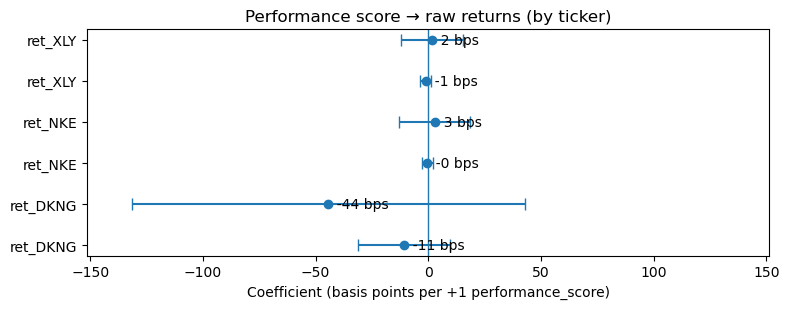

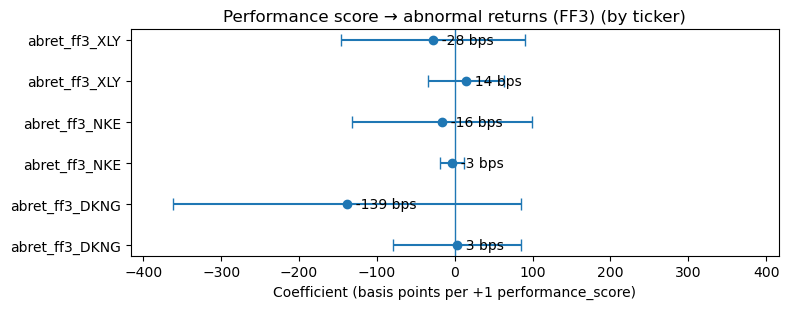

In [6]:
def plot_perfscore_by_outcome(df, outcome_prefix, title):
    sub = df[(df["param"]=="performance_score") & (df["outcome"].str.startswith(outcome_prefix))].copy()
    if sub.empty:
        print("No rows found for", outcome_prefix)
        return

    # y labels: outcome itself (ret_NKE etc)
    sub = sub.sort_values("outcome")
    sub["coef_bps"] = sub["coef"]*10000
    sub["ci_low_bps"] = sub["ci_low"]*10000
    sub["ci_high_bps"] = sub["ci_high"]*10000

    max_abs = np.nanmax(np.abs(np.r_[sub["ci_low_bps"], sub["ci_high_bps"]]))
    pad = 0.15*max_abs if np.isfinite(max_abs) else 10
    xlim = (-max_abs-pad, max_abs+pad)

    fig, ax = plt.subplots(figsize=(8, 3.2))
    y = np.arange(len(sub))

    ax.errorbar(sub["coef_bps"], y, 
                xerr=[sub["coef_bps"]-sub["ci_low_bps"], sub["ci_high_bps"]-sub["coef_bps"]],
                fmt="o", capsize=4)
    ax.axvline(0, linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["outcome"])
    ax.set_xlim(*xlim)
    ax.set_title(title)
    ax.set_xlabel("Coefficient (basis points per +1 performance_score)")

    for yi, v in zip(y, sub["coef_bps"]):
        ax.text(v, yi, f"  {v:.0f} bps", va="center")

    plt.tight_layout()
    plt.show()

plot_perfscore_by_outcome(sector2, "ret_", "Performance score → raw returns (by ticker)")
plot_perfscore_by_outcome(sector2, "abret_ff3_", "Performance score → abnormal returns (FF3) (by ticker)")


## 5) Winter vs non‑winter interaction (interpretation-first)

We show the two coefficients that matter for seasonality:
- `performance_score` (baseline effect in non‑winter)
- `score_x_winter` (how much the effect changes in winter)

So winter effect = `performance_score + score_x_winter`.

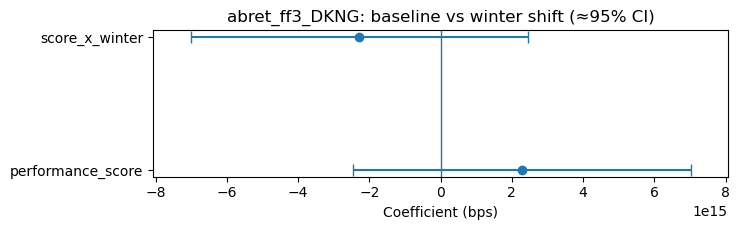

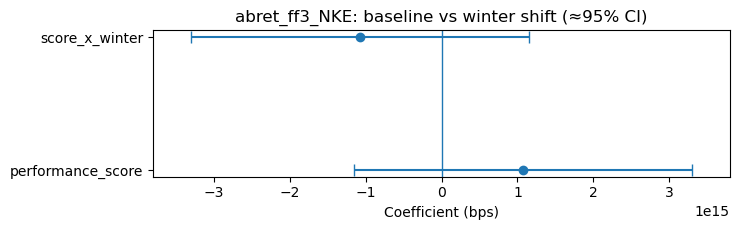

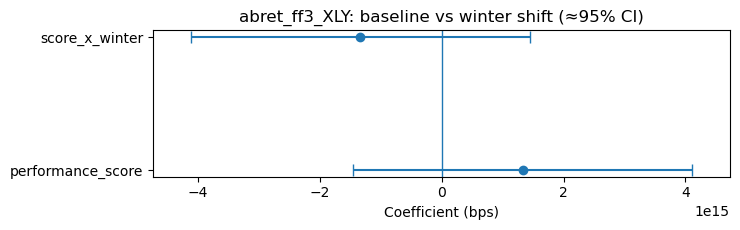

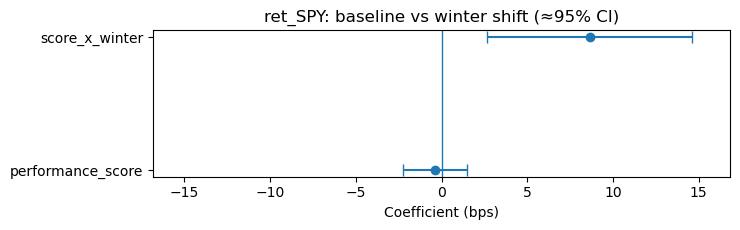

In [7]:
KEY = ["performance_score","score_x_winter"]

for out in sorted(season2["outcome"].unique()):
    sub = season2[(season2["outcome"]==out) & (season2["param"].isin(KEY))].copy()
    if sub.empty:
        continue

    show_bps = out.startswith("ret_") or out.startswith("abret_") or out=="ret_SPY"
    scale = 10000 if show_bps else 1
    unit = "bps" if show_bps else "coef"

    sub["coef_s"] = sub["coef"]*scale
    sub["ci_low_s"] = sub["ci_low"]*scale
    sub["ci_high_s"] = sub["ci_high"]*scale

    order = {p:i for i,p in enumerate(KEY)}
    sub["order"] = sub["param"].map(order)
    sub = sub.sort_values("order")

    max_abs = np.nanmax(np.abs(np.r_[sub["ci_low_s"].values, sub["ci_high_s"].values]))
    pad = 0.15*max_abs
    xlim = (-max_abs-pad, max_abs+pad)

    fig, ax = plt.subplots(figsize=(7.5, 2.4))
    y = np.arange(len(sub))
    ax.errorbar(sub["coef_s"], y,
                xerr=[sub["coef_s"]-sub["ci_low_s"], sub["ci_high_s"]-sub["coef_s"]],
                fmt="o", capsize=4)
    ax.axvline(0, linewidth=1)
    ax.set_yticks(y); ax.set_yticklabels(sub["param"])
    ax.set_xlim(*xlim)
    ax.set_title(f"{out}: baseline vs winter shift (≈95% CI)")
    ax.set_xlabel(f"Coefficient ({unit})")
    plt.tight_layout()
    plt.show()


## 6) Lead/Lag timing check (most intuitive format)

For each outcome we plot **three points**:
- lag (yesterday)
- same day
- lead (tomorrow)

If the **lead** is non‑zero, that can indicate leakage / spurious correlation.  
(Shown in **bps** for return-like outcomes.)

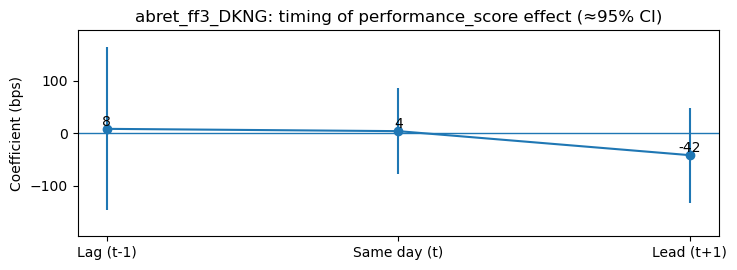

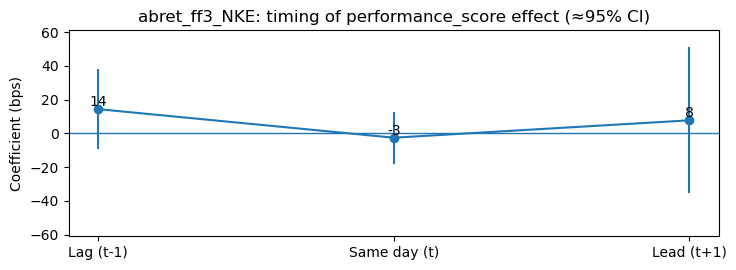

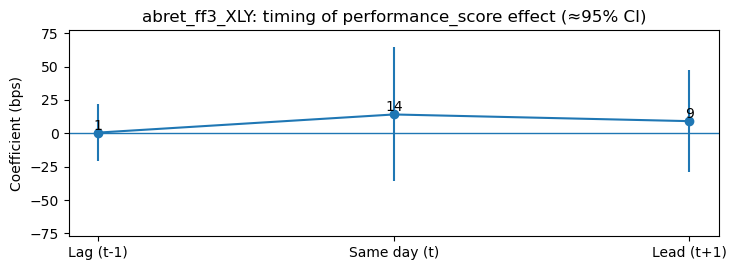

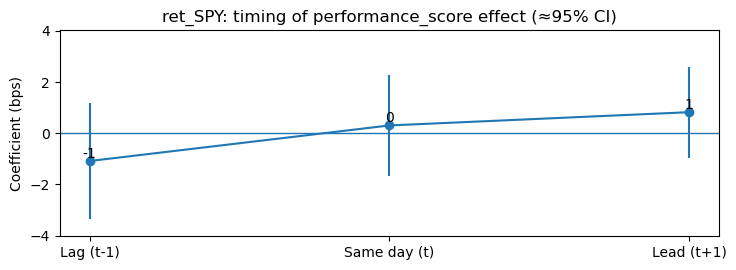

In [8]:
TIMING = ["score_lag1","performance_score","score_lead1"]
LABEL = {"score_lag1":"Lag (t-1)","performance_score":"Same day (t)","score_lead1":"Lead (t+1)"}

for out in sorted(ll2["outcome"].unique()):
    sub = ll2[(ll2["outcome"]==out) & (ll2["param"].isin(TIMING))].copy()
    if sub.empty:
        continue

    show_bps = out.startswith("ret_") or out.startswith("abret_") or out=="ret_SPY"
    scale = 10000 if show_bps else 1
    unit = "bps" if show_bps else "coef"

    sub["coef_s"] = sub["coef"]*scale
    sub["ci_low_s"] = sub["ci_low"]*scale
    sub["ci_high_s"] = sub["ci_high"]*scale

    sub["order"] = sub["param"].map({p:i for i,p in enumerate(TIMING)})
    sub = sub.sort_values("order")

    x = np.arange(len(sub))
    y = sub["coef_s"].values

    # symmetric y-limits
    max_abs = np.nanmax(np.abs(np.r_[sub["ci_low_s"].values, sub["ci_high_s"].values]))
    pad = 0.20*max_abs if np.isfinite(max_abs) else 1
    ylim = (-max_abs-pad, max_abs+pad)

    fig, ax = plt.subplots(figsize=(7.5, 2.8))
    ax.plot(x, y, marker="o")
    ax.axhline(0, linewidth=1)

    # vertical error bars
    for xi, row in zip(x, sub.itertuples(index=False)):
        ax.vlines(xi, row.ci_low_s, row.ci_high_s)

    ax.set_xticks(x)
    ax.set_xticklabels([LABEL[p] for p in sub["param"]])
    ax.set_ylim(*ylim)
    ax.set_title(f"{out}: timing of performance_score effect (≈95% CI)")
    ax.set_ylabel(f"Coefficient ({unit})")

    # annotate values
    for xi, yi in zip(x, y):
        ax.text(xi, yi, f"{yi:.0f}" if show_bps else f"{yi:.4f}", ha="center", va="bottom")

    plt.tight_layout()
    plt.show()


## 7) Event‑study CAR summary (clear percent scales)

Two plots:
1) Scatter: CAR(-1,+1) vs CAR(-1,+3) with **y=x** reference line  
2) Bar chart: CAR(-1,+3) by ticker (sorted)

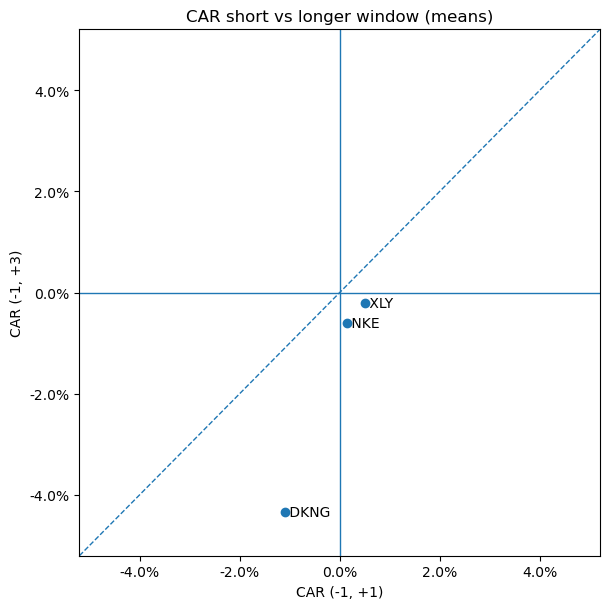

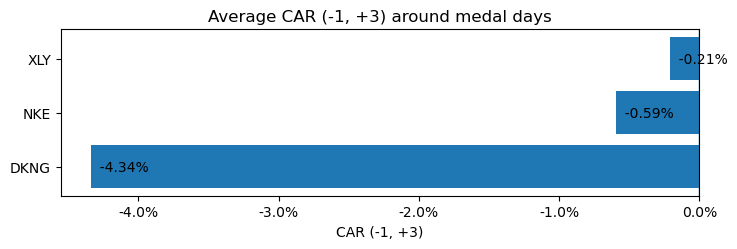

,ticker,CAR_-1_+1_mean,CAR_-1_+1_n,CAR_-1_+3_mean,CAR_-1_+3_n
0,NKE,0.001361,15,-0.005926,15
1,XLY,0.005115,15,-0.002124,15
2,DKNG,-0.010919,15,-0.043356,15


In [10]:
required = {"ticker","CAR_-1_+1_mean","CAR_-1_+3_mean"}
if not required.issubset(car.columns):
    raise ValueError("CAR summary missing expected columns. Found: " + ", ".join(car.columns))

car2 = car.copy()

# --- (1) Scatter with y=x ---
x = car2["CAR_-1_+1_mean"]
y = car2["CAR_-1_+3_mean"]

max_abs = np.max(np.abs(np.r_[x.values, y.values]))
pad = 0.20*max_abs if max_abs > 0 else 0.01
lim = (-max_abs-pad, max_abs+pad)

fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.scatter(x, y)
for _, r in car2.iterrows():
    ax.text(r["CAR_-1_+1_mean"], r["CAR_-1_+3_mean"], f" {r['ticker']}", va="center")

ax.plot(lim, lim, linestyle="--", linewidth=1)   # y = x reference
ax.axhline(0, linewidth=1)
ax.axvline(0, linewidth=1)
ax.set_xlim(*lim); ax.set_ylim(*lim)
ax.xaxis.set_major_formatter(FuncFormatter(percent))
ax.yaxis.set_major_formatter(FuncFormatter(percent))

ax.set_title("CAR short vs longer window (means)")
ax.set_xlabel("CAR (-1, +1)")
ax.set_ylabel("CAR (-1, +3)")
plt.tight_layout()
plt.show()

# --- (2) Sorted bar chart for CAR(-1,+3) ---
car3 = car2.sort_values("CAR_-1_+3_mean")
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.barh(car3["ticker"], car3["CAR_-1_+3_mean"])
ax.axvline(0, linewidth=1)
ax.xaxis.set_major_formatter(FuncFormatter(percent))
ax.set_title("Average CAR (-1, +3) around medal days")
ax.set_xlabel("CAR (-1, +3)")
for yi, v in enumerate(car3["CAR_-1_+3_mean"]):
    ax.text(v, yi, f"  {v*100:.2f}%", va="center")
plt.tight_layout()
plt.show()

display(car2)
